## Análise de atenção: SSVEP + ritmo beta

*Kalil Nege — RA 2409020 · OPT098 - Tópicos Especiais em Sistemas de Computação (Prof. Dr. Rodrigo Hübner)*

Este notebook liga o desenvolvimento à revisão de literatura. Wei et al. (IEEE TNSRE, 2026) mostram que dá para prever a queda de atenção combinando o SSVEP com a potência beta e a razão teta/beta (TBR): mais atenção → SSVEP mais forte, beta mais alta e TBR mais baixa.

O BETA não tem rótulo de atenção, então a análise é exploratória. Como o estímulo cai dentro da banda beta, uso duas versões dos ritmos nos canais frontais/centrais:

- **antes do estímulo** (0,5 s sem SSVEP): é a medida principal e indica o estado da pessoa antes de cada ensaio;
- **durante o estímulo** (2 s, a mesma do notebook 03): para comparar.

Cada participante tem 160 ensaios que não são independentes entre si. Por isso resumo cada pessoa em um único número e faço os testes entre os 70 participantes.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from scipy.stats import spearmanr, wilcoxon

fs = 250
F = np.load('dados/caracteristicas.npy')
meta = np.load('dados/meta.npy')
NOMES = list(np.load('dados/nomes_caracteristicas.npy'))
suj, y, alvo = meta[:, 0].astype(int), meta[:, 2].astype(int), meta[:, 3]
SUJEITOS = np.unique(suj)


def ritmo_pre(x):
    f, P = signal.periodogram(x, fs=fs, window='hann', axis=-1)
    P = P.mean(axis=0)
    total = P[(f >= 4) & (f < 40)].sum()
    teta = P[(f >= 4) & (f < 8)].sum()
    beta = P[(f >= 13) & (f < 30)].sum()
    return beta / total, teta / beta


pre = np.array([ritmo_pre(np.load(f'dados/epocas/S{s}.npz')['ritmo_pre'][b, c])
                for s in SUJEITOS for b in range(4) for c in range(40)])
durante = F[:, [NOMES.index('rel_beta'), NOMES.index('razao_teta_beta')]]
versoes = {'antes do estímulo': pre, 'durante o estímulo': durante}


def rho_sujeito(a, b):
    return np.array([spearmanr(a[suj == s], b[suj == s])[0] for s in SUJEITOS])

### As medidas dependem da frequência do alvo?

Uma medida do estado da pessoa não deveria mudar com o alvo. Para cada participante, calculo a correlação de Spearman entre a frequência do alvo e a medida, e testo (Wilcoxon) se as 70 correlações são diferentes de zero.

In [2]:
for k, nome in enumerate(('beta', 'TBR')):
    for rotulo, v in versoes.items():
        rhos = rho_sujeito(alvo, v[:, k])
        print(f'{nome:<5} {rotulo:<19} rho mediano = {np.median(rhos):+.3f}  p = {wilcoxon(rhos).pvalue:.1e}')

beta  antes do estímulo   rho mediano = -0.005  p = 9.9e-01
beta  durante o estímulo  rho mediano = +0.043  p = 1.1e-04
TBR   antes do estímulo   rho mediano = +0.008  p = 9.6e-01
TBR   durante o estímulo  rho mediano = -0.026  p = 1.6e-03


### Os ritmos acompanham a força do SSVEP?

A força do SSVEP de cada ensaio é o **SNR de banda estreita na frequência do alvo**. Não uso o de banda larga porque ele tem a potência de todo o espectro (inclusive o beta) no denominador, o que criaria uma correlação artificial.

SNR × beta  antes do estímulo   rho mediano = +0.004  (53% positivos, p = 0.357)
SNR × beta  durante o estímulo  rho mediano = +0.022  (63% positivos, p = 0.007)
SNR × TBR   antes do estímulo   rho mediano = +0.009  (56% positivos, p = 0.671)
SNR × TBR   durante o estímulo  rho mediano = -0.035  (33% positivos, p = 0.005)


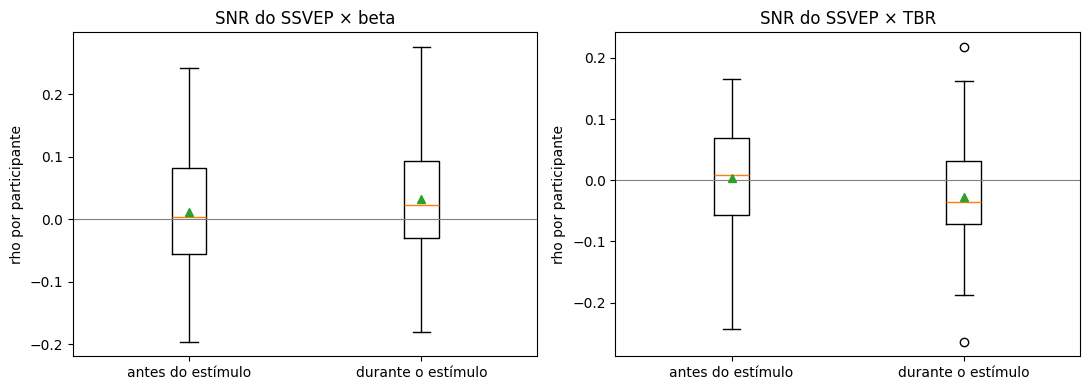

In [3]:
snr_alvo = F[np.arange(len(F)), NOMES.index(f'snr_e_{alvo.min():.1f}') + y]

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for k, (eixo, nome) in enumerate(zip(eixos, ('beta', 'TBR'))):
    dados = []
    for rotulo, v in versoes.items():
        rhos = rho_sujeito(snr_alvo, v[:, k])
        dados.append(rhos)
        print(f'SNR × {nome:<5} {rotulo:<19} rho mediano = {np.median(rhos):+.3f}  '
              f'({np.mean(rhos > 0) * 100:.0f}% positivos, p = {wilcoxon(rhos).pvalue:.3f})')
    eixo.boxplot(dados, showmeans=True)
    eixo.set_xticks([1, 2], versoes.keys()); eixo.axhline(0, c='gray', lw=.8)
    eixo.set_ylabel('rho por participante'); eixo.set_title(f'SNR do SSVEP × {nome}')
plt.tight_layout(); plt.show()

### Entre participantes

Quem tem mais beta ou menos TBR tem uma BCI melhor? Os autores deixaram nos arquivos o **quociente BCI** de cada participante, uma escala de desempenho com média 100 calculada a partir do SNR.

beta antes do estímulo   × quociente BCI: rho = +0.262  (p = 0.029)
TBR antes do estímulo    × quociente BCI: rho = -0.209  (p = 0.082)
beta durante o estímulo  × quociente BCI: rho = +0.306  (p = 0.010)
TBR durante o estímulo   × quociente BCI: rho = -0.280  (p = 0.019)


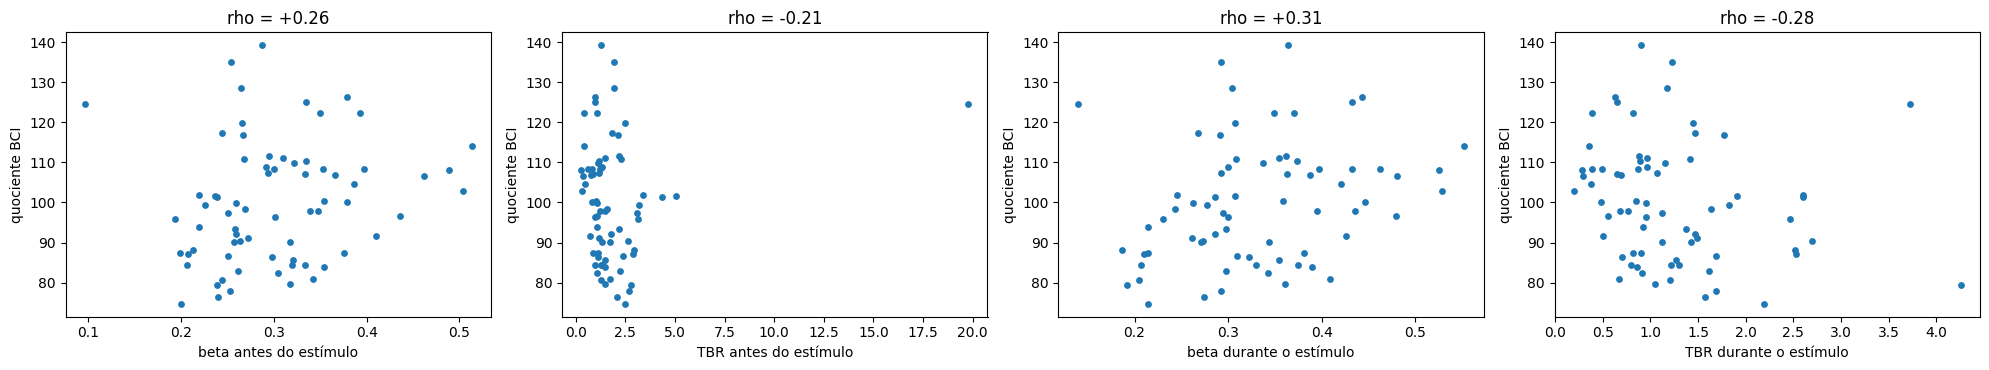

In [4]:
quociente = np.loadtxt('dados/participantes.csv', delimiter=',', skiprows=1)[:, 4]

fig, eixos = plt.subplots(1, 4, figsize=(20, 3.8))
graficos = [(f'{n} {r}', v[:, k]) for r, v in versoes.items() for k, n in enumerate(('beta', 'TBR'))]
for eixo, (nome, v) in zip(eixos, graficos):
    m = np.array([v[suj == s].mean() for s in SUJEITOS])
    r, p = spearmanr(m, quociente)
    print(f'{nome:<24} × quociente BCI: rho = {r:+.3f}  (p = {p:.3f})')
    eixo.scatter(m, quociente, s=15)
    eixo.set_xlabel(nome); eixo.set_ylabel('quociente BCI'); eixo.set_title(f'rho = {r:+.2f}')
plt.tight_layout(); plt.show()

### Discussão

- **Antes do estímulo**, beta e TBR não dependem do alvo, como esperado para uma medida sem SSVEP. **Durante o estímulo**, dependem um pouco (p < 0,01): ainda há um resto de SSVEP nos canais frontais.
- **Dentro de cada participante**, os ritmos antes do estímulo não acompanham a força do SSVEP (rho ≈ 0). Durante o estímulo aparecem correlações na direção prevista (mais beta e menos TBR com SSVEP mais forte), mas muito pequenas (|rho| ≈ 0,02–0,03), e podem ser só esse resto de contaminação.
- **Entre participantes** aparece um indício: quem tem mais beta e menos TBR tem um quociente BCI maior (rho entre 0,21 e 0,31). A direção é a prevista por Wei et al., mas são 4 testes, e com a correção de Bonferroni só o beta durante o estímulo continua abaixo de 0,05.

**Limitações**: o BETA não tem rótulo de atenção, os ensaios são curtos (2–3 s), a janela antes do estímulo tem só 0,5 s e os participantes eram competidores experientes em BCI, provavelmente atentos o tempo todo. Para testar a hipótese de verdade seria preciso uma base com tarefa comportamental (por exemplo, *go/no-go*) ou sessões longas gravadas com o OpenBCI do laboratório.